In [2]:
# CÂU a, b, c, d
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

# Đọc MNIST
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Kích thước ban đầu tập train:", train_images.shape, train_labels.shape)
print("Kích thước tập test:", test_images.shape, test_labels.shape)

# Chuẩn hóa về [0, 1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# Chia train thành train và validation (8:2)
train_images, val_images, train_labels, val_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42
)
print(f"Kích thước sau khi tách - Train: {train_images.shape}, Validation: {val_images.shape}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước ban đầu tập train: (60000, 28, 28) (60000,)
Kích thước tập test: (10000, 28, 28) (10000,)
Kích thước sau khi tách - Train: (48000, 28, 28), Validation: (12000, 28, 28)


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9041 - loss: 0.3285 - val_accuracy: 0.9528 - val_loss: 0.1649
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9535 - loss: 0.1585 - val_accuracy: 0.9638 - val_loss: 0.1202
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9651 - loss: 0.1175 - val_accuracy: 0.9697 - val_loss: 0.1015
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9717 - loss: 0.0958 - val_accuracy: 0.9718 - val_loss: 0.0914
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9755 - loss: 0.0793 - val_accuracy: 0.9747 - val_loss: 0.0826


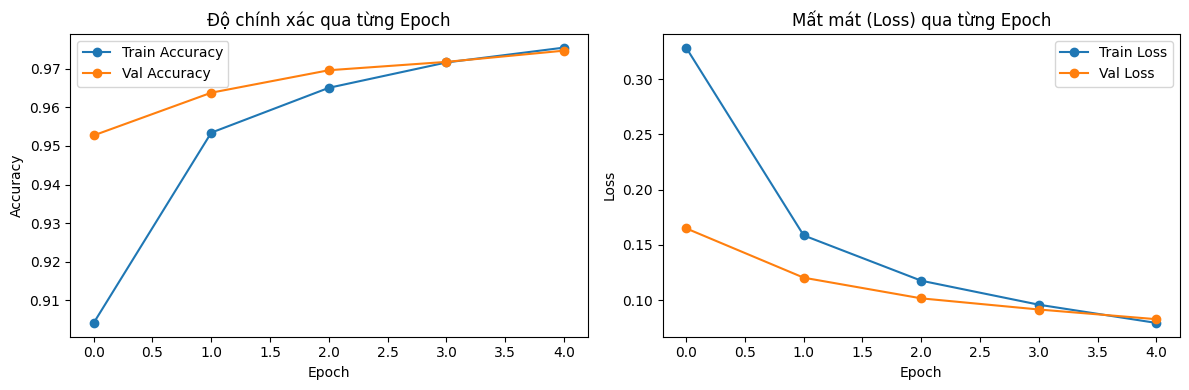

In [3]:
# CÂU e, f, g, h
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, validation_data=(val_images, val_labels), epochs=5, batch_size=32)

# Vẽ biểu đồ Accuracy và Loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Độ chính xác qua từng Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Mất mát (Loss) qua từng Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy trên tập test: 97.33%

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.97      0.97      0.97      1032
           3       0.95      0.98      0.97      1010
           4       0.98      0.97      0.98       982
           5       0.98      0.96      0.97       892
           6       0.98      0.97      0.98       958
           7       0.98      0.94      0.96      1028
           8       0.96      0.98      0.97       974
           9       0.96      0.97      0.97      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



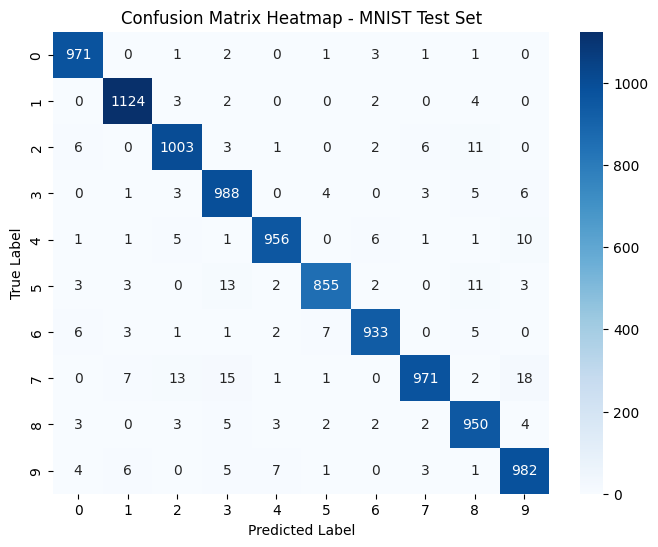

In [4]:
# CÂU i, j, k, l
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print(f"Accuracy trên tập test: {accuracy_score(test_labels, y_pred)*100:.2f}%\n")
print("Báo cáo phân loại chi tiết:")
print(classification_report(test_labels, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(test_labels, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix Heatmap - MNIST Test Set")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


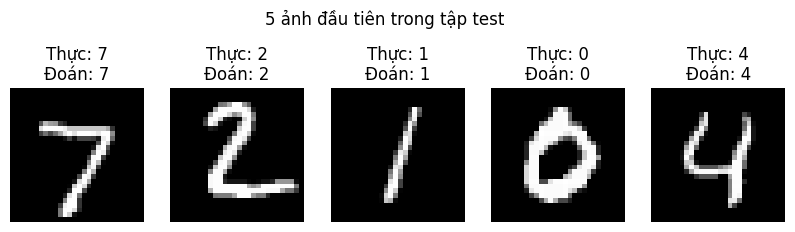

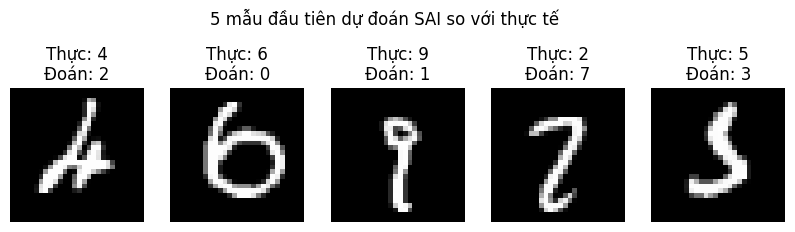

In [5]:
# CÂU m & n
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Phân lớp 5 ảnh đầu tiên
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    img = test_images[i]
    pred = np.argmax(model.predict(np.expand_dims(img, axis=0), verbose=0))
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Thực: {test_labels[i]}\nĐoán: {pred}")
    axes[i].axis('off')
plt.suptitle("5 ảnh đầu tiên trong tập test")
plt.show()

# 5 kết quả đầu tiên bị phân lớp sai
wrong_indices = np.where(y_pred != test_labels)[0][:5]
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for idx, i in enumerate(wrong_indices):
    axes[idx].imshow(test_images[i], cmap='gray')
    axes[idx].set_title(f"Thực: {test_labels[i]}\nĐoán: {y_pred[i]}")
    axes[idx].axis('off')
plt.suptitle("5 mẫu đầu tiên dự đoán SAI so với thực tế")
plt.show()